# 09 · Ensembles: how sure are we about the capture zone?

Every capture zone so far came from one model with one set of parameters. The hydraulic conductivity of a real aquifer is never known that well: a calibrated model is one of many parameter sets that fit the data about equally well. Tools such as PEST++ IES produce exactly that, an **ensemble** of parameter realisations, and the honest answer to "which cells feed the well?" is then a **probability**.

This tutorial runs the trace over an ensemble of random conductivity fields. You will:

1. build 20 realisations of the quickstart aquifer with random, spatially correlated K;
2. run the ensemble driver `gs.run_ensemble`, which traces every realisation and keeps only running statistics;
3. map the **capture probability** $P(F > 0.1)$ and $P(F > 0.5)$, and the mean and quantiles of $F$;
4. look at the spread of the well's **shares by source** across realisations;
5. compare **exact and histogram quantiles**, and see when each fits in memory;
6. run realisations **in parallel**;
7. weigh parameter uncertainty against the grid and mixing effects of tutorials 01 and 06;
8. see how this plugs into a **PEST++ IES** workflow (described, not run).

**Runtime:** about 20 seconds. **Prerequisites:** tutorials 01 and 06.

## Settings

All settings live in this first cell. The realisations are written to `tutorials/_work/09_ensembles/` (git-ignored, recreated on every run). Shared builders and plots are in [`herebedragons.py`](../herebedragons.py); a per-realisation summary table and a process-pool check specific to this tutorial are in [`helpers.py`](helpers.py) next to this notebook.

In [1]:
import sys
import time
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
sys.path.insert(0, str(Path.cwd()))  # this folder holds helpers.py
import helpers  # noqa: E402
import herebedragons as hbd  # noqa: E402

import gwsource as gs  # noqa: E402

WORK = hbd.work_dir("09_ensembles", clean=True)  # tutorials/_work/09_ensembles (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
N_REAL = 20  # number of K realisations
ENSEMBLE_SEED = 7  # seeds the realisation seeds
SIGMA_LNK = 0.8  # standard deviation of ln K
CORRELATION_CELLS = 4.0  # smoothing length of the K field, in cells
GROUP = "well"
GROUPS = {GROUP: {"boundnames": ["supply_well"]}}  # select() arguments, applied to every realisation
THRESHOLDS = (0.1, 0.5)  # capture probability P(F > t)
QUANTILES = (0.05, 0.5, 0.95)
POROSITY = 0.3  # for the mean travel time outputs (tutorial 06)
TIME_RANGE = (0.0, 1.5e5)  # histogram range of mean_time (days), for approximate quantiles
TRY_PARALLEL = True  # run the parallel comparison where process pools are allowed
PARALLEL_WORKERS = 2
SOURCE_LABELS = {"RCH": "recharge", "RIV": "river leakage", "CHD": "west edge"}

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. Build the ensemble

`hbd.build_ensemble` writes and runs `N_REAL` copies of the quickstart model (tutorial 01), each in its own folder `real_000`, `real_001`, …, with its own log-normal K field: Gaussian noise smoothed over a few cells, scaled to $\sigma_{\ln K} = 0.8$ around the quickstart's 5 m/d. Everything else (recharge, river, west edge, well) is the same in every realisation, and so is the grid.

This stands in for the posterior ensemble of a history-matching run; section 8 shows how to point the same code at PEST++ IES realisations. We also build the homogeneous quickstart model as a **base case**.

built and ran 20 realisations in 3.0 s


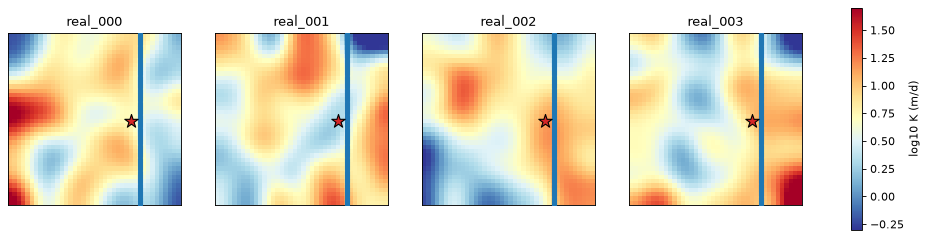

In [2]:
start = time.perf_counter()
folders = hbd.build_ensemble(
    WORK / "ensemble", MF6, N_REAL, seed=ENSEMBLE_SEED, sigma_lnk=SIGMA_LNK,
    correlation_cells=CORRELATION_CELLS,
)
print(f"built and ran {len(folders)} realisations in {time.perf_counter() - start:.1f} s")
base = hbd.build_quickstart(WORK / "base", MF6)
base_step = gs.read_step(base.ws, boundnames=True)
base_res = gs.backward(base_step, {GROUP: gs.select(base_step, **GROUPS[GROUP])})
F_base = base_res.fraction_through[GROUP]

fig, axes = plt.subplots(1, 4, figsize=(16.0, 4.0))
for ax, ws in zip(axes, folders):
    sim = flopy.mf6.MFSimulation.load(sim_ws=str(ws), load_only=["npf"], verbosity_level=0)
    k = sim.get_model().npf.k.array.ravel()
    collection = gs.export.plot_map(base.grb_file, base_step, np.log10(k), ax=ax, cmap="RdYlBu_r",
                                    vmin=-0.3, vmax=1.7)
    hbd.overlay_features(ax, base.grb_file, base_step, packages=("RIV", "WEL"), legend=False)
    ax.set(aspect="equal", title=ws.name, xticks=[], yticks=[])
fig.colorbar(collection, ax=axes, shrink=0.9, label="log10 K (m/d)")
plt.show()

The fields vary by about an order of magnitude over a few hundred metres. Lower-K patches slow the flow and steepen the gradient, so each realisation draws a different capture zone.

## 2. Run the ensemble driver

`gs.run_ensemble(workspaces, groups, config)` does, for each realisation folder:

1. read the time step `config.kstpkper`;
2. re-select the groups from the `select()` arguments (or call a function `step -> groups`), so a group follows its boundary even if node numbers differ;
3. run the backward (or forward) trace, and the travel time when `porosity` is set;
4. fold the requested per-cell outputs into running statistics: min, max, mean, exceedance probabilities $P(\text{value} > t)$ and quantiles.

Only one realisation's outputs are in memory at a time (plus the quantile store, section 5). Every realisation must have the same grid: the connectivity arrays are hashed and compared with the first realisation's.

The well is selected by its boundname. Boundnames are not in the budget file, so `boundnames=True` makes the driver load them from each realisation's package input (FloPy); without it, select by package, bound number or cell.

In [3]:
workspaces = gs.list_realisations(WORK / "ensemble", "real_*")
config = gs.EnsembleConfig(
    outputs=("fraction_through", "mean_time"),
    thresholds=THRESHOLDS,
    quantiles=QUANTILES,
    porosity=POROSITY,
    histogram_range={"mean_time": TIME_RANGE},
    boundnames=True,  # GROUPS selects the well by boundname
)
start = time.perf_counter()
ens = gs.run_ensemble(workspaces, GROUPS, config)
serial_time = time.perf_counter() - start
print(f"{len(ens.realisations)} realisations traced in {serial_time:.2f} s; "
      f"outputs {ens.outputs}; quantiles: {ens.quantile_method}")
print(f"well inflow per realisation: {ens.group_inflow[GROUP].min():.1f} to {ens.group_inflow[GROUP].max():.1f} m3/d")
transit = ens.mean_transit_time[GROUP] / 365.25
print(f"mean travel time to the well (sum V F / Q): {transit.min():.0f} to {transit.max():.0f} yr "
      f"(median {np.median(transit):.0f} yr)")

20 realisations traced in 0.84 s; outputs ['fraction_through', 'mean_time']; quantiles: exact
well inflow per realisation: 800.0 to 800.0 m3/d
mean travel time to the well (sum V F / Q): 35 to 56 yr (median 45 yr)


Tracing 20 realisations of 1600 cells takes a fraction of a second; building and running the MF6 models took most of the time. The well rate is the same in every realisation, so the inflow is 800 m³/d throughout, while the mean travel time (tutorial 06's $\sum V F / Q$) varies by about half.

## 3. Capture probability

`ens.exceedance[t]["fraction_through"][group]` is, for every cell, the share of realisations in which $F > t$:

- $P(F > 0.5)$: the probability that the cell lies inside the advective capture zone (tutorial 01: $F = 0.5$ is the best estimate of that zone's edge);
- $P(F > 0.1)$: the probability that the cell lies inside the conservative outline.

The dashed line is the base case's $F = 0.5$ contour.

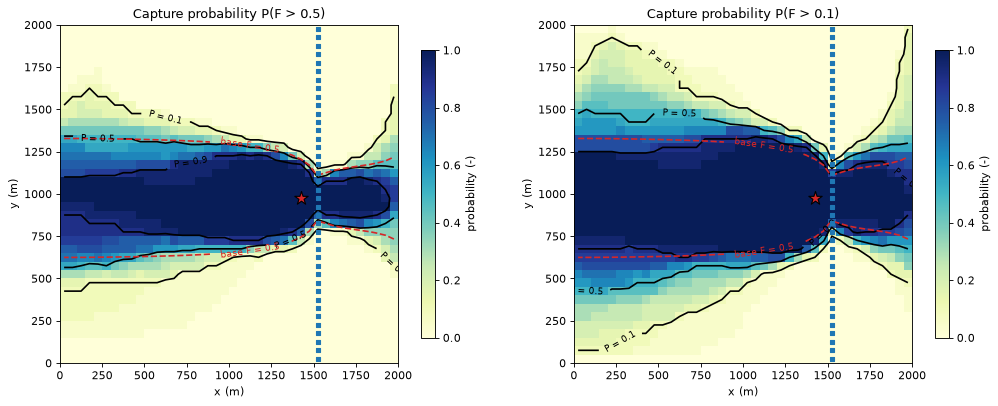

,area P >= 0.9 (km2),area P >= 0.5 (km2),area P >= 0.1 (km2),area P > 0 (km2)
P(F > 0.1),1.142,1.622,2.415,2.685
P(F > 0.5),0.745,1.138,1.692,1.985


base case: area F > 0.5 = 1.143 km2, F > 0.1 = 1.575 km2


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0))
for ax, t in zip(axes, (0.5, 0.1)):
    prob = ens.exceedance[t]["fraction_through"][GROUP]
    hbd.plot_cells(
        base.grb_file, base_step, prob, ax=ax, cmap="YlGnBu", vmin=0.0, vmax=1.0,
        title=f"Capture probability P(F > {t})", label="probability (-)", overlay=False,
    )
    hbd.add_contours(ax, base.grb_file, base_step, prob, (0.1, 0.5, 0.9), colors="k", fmt="P = %.1f")
    hbd.add_contours(ax, base.grb_file, base_step, F_base, (0.5,), colors="tab:red",
                     linestyles=["--"], fmt="base F = %.1f")
    hbd.overlay_features(ax, base.grb_file, base_step, packages=("RIV", "WEL"), legend=False)
fig.tight_layout()
plt.show()

area = base_step.area
rows = {}
for t in THRESHOLDS:
    prob = ens.exceedance[t]["fraction_through"][GROUP]
    rows[f"P(F > {t})"] = {f"area P >= {p} (km2)": area[prob >= p].sum() / 1e6 for p in (0.9, 0.5, 0.1)}
    rows[f"P(F > {t})"]["area P > 0 (km2)"] = area[prob > 0].sum() / 1e6
display(pd.DataFrame(rows).T.round(3))
print(f"base case: area F > 0.5 = {area[F_base > 0.5].sum() / 1e6:.3f} km2, "
      f"F > 0.1 = {area[F_base > 0.1].sum() / 1e6:.3f} km2")

How to read the maps:

- The **dark core** ($P \ge 0.9$) is captured in nearly every realisation: the cells around the well and along the main flow path from the west. Protection there does not depend on knowing K better.
- The **gradient** between $P = 0.9$ and $P = 0.1$ is where the capture zone's position depends on the K field: the zone swings north or south as low-K patches deflect the flow.
- The **outer limit** ($P > 0$) is the union of all realisations' zones: an upper bound that grows with the ensemble size, not a probability statement.

A protection zone can then be drawn with an explicit risk level, for example "every cell with at least a 10 % chance of being inside the advective capture zone", $P(F > 0.5) \ge 0.1$. The two thresholds combine two different uncertainties: $P(F > 0.1)$ adds the conservative margin for numerical mixing (tutorial 01) on top of the parameter uncertainty.

## 4. Mean and quantile maps

`ens.stats["mean"]` and `ens.quantiles[q]` give the per-cell mean and quantiles over the realisations.

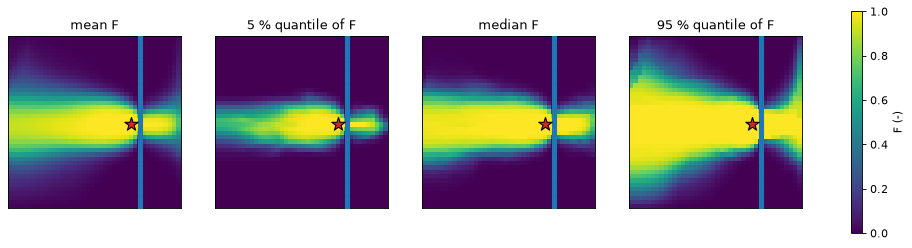

In [5]:
panels = {
    "mean F": ens.stats["mean"]["fraction_through"][GROUP],
    "5 % quantile of F": ens.quantiles[0.05]["fraction_through"][GROUP],
    "median F": ens.quantiles[0.5]["fraction_through"][GROUP],
    "95 % quantile of F": ens.quantiles[0.95]["fraction_through"][GROUP],
}
fig, axes = plt.subplots(1, 4, figsize=(16.0, 4.0))
for ax, (title, values) in zip(axes, panels.items()):
    collection = gs.export.plot_map(base.grb_file, base_step, values, ax=ax, cmap="viridis",
                                    vmin=0.0, vmax=1.0)
    hbd.overlay_features(ax, base.grb_file, base_step, packages=("RIV", "WEL"), legend=False)
    ax.set(aspect="equal", title=title, xticks=[], yticks=[])
fig.colorbar(collection, ax=axes, shrink=0.9, label="F (-)")
plt.show()

The mean of $F$ looks like a smoothed capture zone: it is the expected fraction of each cell's water that reaches the well, averaging the parameter uncertainty and the numerical mixing together. The quantile maps are **per cell**: the 5 % map is not the capture zone of a "small" realisation, but the value each cell exceeds in 95 % of the realisations. Where the 5 % quantile is high, the cell is captured whatever the K field; where the 95 % quantile is still low, it almost never is.

## 5. The well's water by source, across realisations

The split of the pumped water by source package is a sum over cells, not a per-cell output, so `helpers.summarise_realisations` traces each realisation once more and tabulates the shares (the same table as `hbd.volume_from_table` in tutorial 01) and the capture areas.

,share RIV,share RCH,share CHD,area F>0.1 (km2),area F>0.5 (km2),mean travel time (yr)
mean,0.117,0.695,0.188,1.650,1.132,45.043
std,0.087,0.088,0.093,0.217,0.145,5.847
min,0.006,0.538,0.036,1.222,0.888,34.585
50%,0.108,0.700,0.172,1.666,1.132,45.018
max,0.282,0.854,0.365,2.045,1.410,55.767


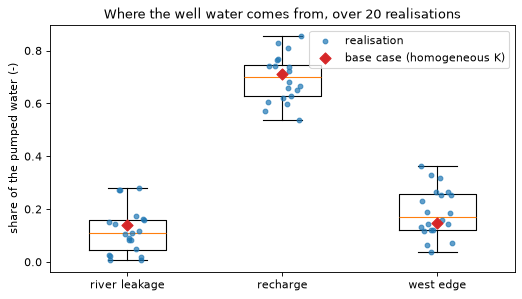

In [6]:
table = helpers.summarise_realisations(workspaces, GROUP, GROUPS[GROUP], THRESHOLDS)
table["mean travel time (yr)"] = ens.mean_transit_time[GROUP] / 365.25
share_cols = [c for c in table.columns if c.startswith("share ")]
display(table.describe().loc[["mean", "std", "min", "50%", "max"]].round(3))

shares = table[share_cols].rename(columns=lambda c: SOURCE_LABELS.get(c[6:], c[6:]))
base_shares = hbd.volume_from_table(base_res, GROUP)["share"].rename(SOURCE_LABELS)
fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.boxplot([shares[c] for c in shares.columns], positions=range(len(shares.columns)), widths=0.5,
           showfliers=False)
rng = np.random.default_rng(0)
for i, column in enumerate(shares.columns):
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(shares)), shares[column], s=18, alpha=0.7,
               color="tab:blue", label="realisation" if i == 0 else None, zorder=3)
    ax.scatter(i, base_shares.get(column, np.nan), marker="D", s=50, color="tab:red",
               label="base case (homogeneous K)" if i == 0 else None, zorder=4)
ax.set_xticks(range(len(shares.columns)), shares.columns)
ax.set_ylabel("share of the pumped water (-)")
ax.set_title(f"Where the well water comes from, over {len(shares)} realisations")
ax.legend(loc="upper right")
plt.show()

Recharge always supplies most of the water, but its share varies between about 55 and 85 %. The river share is the most uncertain: from almost nothing to more than a quarter of the pumping, depending on whether low-K patches sit between the well and the river. That is the number a riverbank-filtration or water-quality assessment would ask for, and one model run would have given a single value somewhere in this range. The homogeneous base case falls inside the spread of every source; a single model run gives no hint of how wide that spread is.

## 6. Exact and histogram quantiles

Min, max, mean and exceedance are running sums, so their memory does not grow with the number of realisations. Quantiles need more:

- **Exact:** keep every realisation's values in a float32 stack, (realisations × cells × series) × 4 bytes, where a *series* is one output of one group. The driver does this when the stack fits `config.memory_budget` (2 GB by default).
- **Histogram:** otherwise, keep a fixed-bin histogram per cell: bins × cells × series × 4 bytes, *independent of the number of realisations*. A quantile is then accurate to one bin width, (high − low) / bins, over `config.histogram_range` (default (0, 1), right for fractions; set it for times and volumes, as above).

Forcing the histogram path with `memory_budget=0` and comparing:

In [7]:
approx = gs.run_ensemble(workspaces, GROUPS, gs.EnsembleConfig(**{**vars(config), "memory_budget": 0}))
print("quantile method:", approx.quantile_method)
rows = {}
for output in config.outputs:
    low, high = config.bin_range(output)
    defined = ens.stats["count"][output][GROUP] > 0
    beyond = defined & (ens.stats["max"][output][GROUP] > high + 1e-9 * (high - low))  # beyond round-off
    diff = helpers.max_quantile_difference(ens, approx, output, GROUP)
    rows[output] = {
        "range": f"{low:g} to {high:g}",
        "bin width": f"{approx.bin_width[output]:.3g}",
        **{f"max |diff| q={q} (in range)": f"{d:.3g}" for q, d in diff.items()},
        "cells with values above the range": int(beyond.sum()),
    }
display(pd.DataFrame(rows).T)
largest = np.nanmax(ens.stats["max"]["mean_time"][GROUP])
print(f"largest mean_time in any cell and realisation: {largest:.3g} d ({largest / 365.25:.0f} yr)")

quantile method: histogram


,range,bin width,max |diff| q=0.05 (in range),max |diff| q=0.5 (in range),max |diff| q=0.95 (in range),cells with values above the range
fraction_through,0 to 1,0.005,0.00443,0.00416,0.00415,0
mean_time,0 to 150000,750,498,478,503,45


largest mean_time in any cell and realisation: 3.67e+06 d (10034 yr)


Where a cell's values lie inside the histogram range, every histogram quantile is within one bin width of the exact one; the means, minima, maxima and probabilities do not depend on the quantile method at all. Two lessons:

- **The bin width is the price of the range.** For fractions, (0, 1) in 200 bins gives 0.005; for `mean_time`, (0, 150,000 d) gives bins of 750 days.
- **Outside the range there is no bound.** Values beyond it are counted in the end bins, so a quantile there is only clamped to the cell's minimum and maximum. The conditional mean time of cells on the far edge of the capture zone, where only a tiny fraction of the water reaches the well, reaches thousands of years, far beyond any useful range. Set `histogram_range` to cover the values you care about, and mask such cells (by $F$ or by the capture probability) before using their times.

The **memory budget** decides between the two. For a regional model of a million cells and, say, three outputs of two groups (six series):

In [8]:
cells, series, bins = 1_000_000, 6, config.histogram_bins
rows = {
    n_real: {
        "exact stack (GB)": gs.ensemble.stack_bytes(n_real, cells, series) / 1e9,
        "histograms (GB)": 4 * bins * cells * series / 1e9,
    }
    for n_real in (20, 100, 300, 1000)
}
display(pd.DataFrame(rows).T.rename_axis("realisations").round(2))
n_series = len(config.outputs) * len(GROUPS)
print(f"this tutorial: exact stack {gs.ensemble.stack_bytes(N_REAL, base_step.n_cells, n_series) / 1e6:.2f} MB")

,exact stack (GB),histograms (GB)
realisations,,
20,0.48,4.8
100,2.40,4.8
300,7.20,4.8
1000,24.00,4.8


this tutorial: exact stack 0.26 MB


The exact stack grows with the number of realisations; the histograms do not, so they win only once there are more realisations than bins (200 by default). Below that, raise `memory_budget` if the machine allows it and keep exact quantiles; above it, or for outputs you only need roughly, the histograms cap the memory. Fewer series help either way: ask only for the outputs you will use, and aggregate groups (`groups_by_package`, `groups_by_zone`) rather than tracing every well separately.

## 7. Serial and parallel runs

With `max_workers > 1` the driver traces realisations in a `ProcessPoolExecutor` and folds the results back in realisation order, so the statistics are **bit-identical** to a serial run. Two practical points:

- **Process pools need OS support.** They use semaphores and, on macOS and Windows, freshly spawned Python processes. Some sandboxes and restricted job environments forbid this; the check below then skips the parallel run, and `max_workers=1` (the default) always works.
- **Spawned workers re-import the package and cannot see functions defined in a notebook.** Pass groups as a dict of `select()` arguments (as here) or as a function from an importable module.

In [9]:
if TRY_PARALLEL and helpers.process_pool_available():
    start = time.perf_counter()
    par = gs.run_ensemble(workspaces, GROUPS, gs.EnsembleConfig(**{**vars(config), "max_workers": PARALLEL_WORKERS}))
    parallel_time = time.perf_counter() - start
    for output in config.outputs:
        for name in ("mean", "min", "max"):
            np.testing.assert_array_equal(par.stats[name][output][GROUP], ens.stats[name][output][GROUP])
        for q in QUANTILES:
            np.testing.assert_array_equal(par.quantiles[q][output][GROUP], ens.quantiles[q][output][GROUP])
    print(f"serial {serial_time:.2f} s, {PARALLEL_WORKERS} workers {parallel_time:.2f} s; statistics bit-identical")
else:
    print("process pools are not available here (or TRY_PARALLEL is False): parallel run skipped")

serial 0.84 s, 2 workers 2.54 s; statistics bit-identical


On a model this small the workers spend more time starting up than tracing, so the parallel run is not faster. Parallel runs pay off when one realisation takes seconds, as for the 250,000-cell benchmark in `PLAN.md` (about 2 s to open the files and 0.4 s per trace).

## 8. Parameter uncertainty or grid and mixing effects: which matters more here?

Tutorials 01 and 06 showed that full mixing smears the capture-zone edge over a band of cells. Here is that band next to the spread caused by K:

In [10]:
p05 = ens.exceedance[0.5]["fraction_through"][GROUP]
area_f05 = table["area F>0.5 (km2)"]
rows = {
    "capture area F > 0.5 (km2)": {
        "parameter spread (5-95 % over realisations)": f"{area_f05.quantile(0.05):.2f} to {area_f05.quantile(0.95):.2f}",
        "grid and mixing effect": "within about 5 % at 50 m cells (dispersion study)",
    },
    "uncertain edge band (km2)": {
        "parameter spread (5-95 % over realisations)": f"{area[(p05 > 0.1) & (p05 < 0.9)].sum() / 1e6:.2f}  (0.1 < P(F > 0.5) < 0.9)",
        "grid and mixing effect": f"{area[(F_base > 0.1) & (F_base < 0.9)].sum() / 1e6:.2f}  (0.1 < F < 0.9, base case)",
    },
    "river share of the well water": {
        "parameter spread (5-95 % over realisations)": f"{table['share RIV'].quantile(0.05):.3f} to {table['share RIV'].quantile(0.95):.3f}",
        "grid and mixing effect": "same to three digits under mixing, face routing and particles",
    },
    "mean travel time (yr)": {
        "parameter spread (5-95 % over realisations)": f"{table['mean travel time (yr)'].quantile(0.05):.0f} to {table['mean travel time (yr)'].quantile(0.95):.0f}",
        "grid and mixing effect": "within 2 to 4 % of particles (tutorial 06: 0.5 % here)",
    },
}
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).T)

,parameter spread (5-95 % over realisations),grid and mixing effect
capture area F > 0.5 (km2),0.91 to 1.39,within about 5 % at 50 m cells (dispersion study)
uncertain edge band (km2),0.77 (0.1 < P(F > 0.5) < 0.9),"0.80 (0.1 < F < 0.9, base case)"
river share of the well water,0.007 to 0.273,"same to three digits under mixing, face routing and particles"
mean travel time (yr),36 to 54,within 2 to 4 % of particles (tutorial 06: 0.5 % here)


For this aquifer, with $\sigma_{\ln K} = 0.8$, **parameter uncertainty dominates** every integral answer: the shares by source, the mean travel time and the size of the capture zone vary by tens of per cent across realisations, while the grid and mixing effects on the same quantities are a few per cent at most ([`docs/dispersion_study.md`](../../docs/dispersion_study.md)). For the **position of the zone edge** the two are comparable: the band of cells where the realisations disagree is of the same order as the band that numerical mixing smears in a single model. Refining the grid sharpens the edge of each realisation's zone; it does not tell you which realisation is right.

Two caveats. This K ensemble is a prior made up for the tutorial; a posterior conditioned on heads and flows is usually narrower, and the balance can shift towards the grid effects. And other parameters (recharge, river conductance, porosity for travel times) add their own spread; an ensemble over all of them is the next step.

## 9. Plugging into a PEST++ IES workflow

PEST++ IES works with an ensemble of parameter realisations and runs the model once per realisation and iteration. There are two places to hook the trace in. The sketches below are not run in this tutorial; adapt the paths and file names to your project.

### (1) Trace the posterior realisations after the run

After history matching, rerun the posterior parameter ensemble (for example `case.3.par.csv`, the parameters of the last iteration) once more, one folder per realisation, and keep the MF6 output. PEST++ sweeps reuse worker folders and do not keep model output per realisation, so write the folders yourself (or have the forward run copy its `.grb` and `.cbc` out). Then trace them all:

```python
import shutil
import subprocess
from pathlib import Path

import pandas as pd

import gwsource as gs


def run_realisation(template_ws: Path, ws: Path, pars: pd.Series, exe: Path) -> None:
    """Copy the PEST template model, apply one parameter realisation and run MF6."""
    shutil.copytree(template_ws, ws, dirs_exist_ok=True)
    write_parameters(ws, pars)  # project-specific: e.g. pyemu's apply_list_and_array_pars, or the forward-run pre-processing
    subprocess.run([str(exe)], cwd=ws, check=True)


pe = pd.read_csv("pest/case.3.par.csv", index_col=0)  # one row per posterior realisation
for real, pars in pe.iterrows():
    run_realisation(Path("pest/template"), Path("posterior") / f"real_{real}", pars, Path("bin/mf6"))

ens = gs.run_ensemble(
    gs.list_realisations("posterior", "real_*"),
    {"supply": {"package": "WEL"}, "river": {"package": "RIV"}},
    gs.EnsembleConfig(thresholds=(0.1, 0.5), max_workers=8),
)
```

`ens.exceedance[0.5]["fraction_through"]["supply"]` is then the posterior capture probability, conditioned on everything the history match learned.

### (2) Make capture fractions observations of the forward run

To let IES carry capture results through every iteration (as forecasts to report, or as targets to constrain), compute them in the forward-run script after MF6 and write them to a file that an instruction file reads. Every realisation then reports them, and IES gives their prior and posterior distributions at no extra cost beyond the trace itself.

```python
# forward_run.py (runs in each PEST++ worker folder)
import subprocess

import numpy as np

import gwsource as gs


def write_capture_observations(ws: str = ".", out_file: str = "capture.csv") -> None:
    """Trace the model in ws and write capture metrics as observations (one per row)."""
    step = gs.read_step(ws)
    res = gs.backward(step, {"supply": gs.select(step, package="WEL")})
    f = res.fraction_through["supply"]
    by_source = {k: float(v.sum()) for k, v in res.volume_from_by_term["supply"].items()}
    total = sum(by_source.values())
    rows = {f"share_{k.lower()}": v / total for k, v in by_source.items()}
    rows["area_f05"] = float(step.area[f > 0.5].sum())
    rows["f_at_spill_site"] = float(f[1234])  # a cell of interest, 0-based node
    with open(out_file, "w") as handle:
        handle.write("name,value\n")
        for name, value in rows.items():
            handle.write(f"{name},{value:.10e}\n")


if __name__ == "__main__":
    subprocess.run(["mf6"], check=True)
    write_capture_observations()
```

With pyemu's `PstFrom` the same function can be added to the forward run and its output registered as observations (check the signatures against your pyemu version):

```python
pf.add_py_function("capture_obs.py", "write_capture_observations()", is_pre_cmd=False)
pf.add_observations("capture.csv", index_cols="name", use_cols=["value"], prefix="cap")
```

Notes for this route:

- `add_py_function` copies the function's source into `forward_run.py`, not module-level constants: the function must be self-contained (imports and settings inside it or passed as arguments).
- Keep the number of observations modest: a few shares, areas or fractions at cells of interest, not a per-cell map of a million cells. Sums such as the shares and areas are also the outputs least affected by numerical mixing.
- Give them weight 0 to treat them as forecasts; non-zero weights would make IES fit them, which only makes sense with real data (e.g. a measured river-water share from isotopes).
- The trace adds well under a second per run for models up to a few hundred thousand cells (`PLAN.md`, Phase 2 benchmarks), small next to the MF6 run.

## 10. Sanity checks

The mean over realisations of the area with $F > 0.5$ must equal the area-weighted sum of $P(F > 0.5)$ (both count the same cells), and the ensemble mean of $F$ must lie between its minimum and maximum:

In [11]:
for t in THRESHOLDS:
    from_probability = float(ens.exceedance[t]["fraction_through"][GROUP] @ area) / 1e6
    from_realisations = table[f"area F>{t} (km2)"].mean()
    print(f"F > {t}: sum P x area = {from_probability:.4f} km2, mean area over realisations = {from_realisations:.4f} km2")
    assert abs(from_probability - from_realisations) < 1e-9
stats = ens.stats
mean_f = stats["mean"]["fraction_through"][GROUP]
assert np.all(stats["min"]["fraction_through"][GROUP] <= mean_f + 1e-12)
assert np.all(mean_f <= stats["max"]["fraction_through"][GROUP] + 1e-12)
assert np.allclose(ens.group_inflow[GROUP], 800.0)

F > 0.1: sum P x area = 1.6498 km2, mean area over realisations = 1.6498 km2
F > 0.5: sum P x area = 1.1321 km2, mean area over realisations = 1.1321 km2


## Key points

- `gs.run_ensemble` traces many realisations of one grid (one folder each) and keeps streaming statistics: min, max, mean, exceedance probabilities and quantiles, for any per-cell output, including travel times when a porosity is given.
- The **capture probability** $P(F > 0.5)$ maps the chance that a cell lies in the advective capture zone; $P(F > 0.1)$ adds the conservative margin for numerical mixing. Protection zones can be drawn at an explicit risk level.
- **Quantile maps are per cell**, not realisations. Exact quantiles keep a float32 stack (memory grows with the number of realisations); histogram quantiles have a fixed memory and an error of at most one bin width.
- **Parallel runs** (`max_workers > 1`) give bit-identical statistics, need process pools, and pay off when a realisation takes seconds.
- For this aquifer, **parameter uncertainty outweighs grid and mixing effects** for shares, travel times and zone size; for the position of the zone edge they are comparable.
- With **PEST++ IES**, either trace the posterior realisation folders after the run, or compute capture metrics in `forward_run.py` so they become observations (forecasts) of every realisation.

## Next

[10 · Unit concentration](../10_unit_concentration/10_unit_concentration.ipynb): the Bedekar et al. (2024) unit-concentration example rebuilt in MF6, tracked forward and backward, and compared with MF6 GWT and the published figure.